In [1]:
import json
import torch
import torch.nn as nn
import math

from pathlib import Path


# Path to processed data
processed_dir = Path("../data/processed")


# Load vocabulary
with open(processed_dir / "vocabulary.json", "r", encoding="utf-8") as f:
    token_to_id = json.load(f)


# Load prepared tensors
train_data = torch.load(processed_dir / "train_tensors.pt")
val_data = torch.load(processed_dir / "val_tensors.pt")
test_data = torch.load(processed_dir / "test_tensors.pt")


print("Vocabulary size:", len(token_to_id))

print("\nTraining data:")
print("Source:", train_data["source"].shape)
print("Decoder input:", train_data["decoder_input"].shape)
print("Decoder target:", train_data["decoder_target"].shape)

print("\nValidation data:")
print("Source:", val_data["source"].shape)
print("Decoder input:", val_data["decoder_input"].shape)
print("Decoder target:", val_data["decoder_target"].shape)

print("\nTest data:")
print("Source:", test_data["source"].shape)
print("Decoder input:", test_data["decoder_input"].shape)
print("Decoder target:", test_data["decoder_target"].shape)

Vocabulary size: 9537

Training data:
Source: torch.Size([800, 512])
Decoder input: torch.Size([800, 127])
Decoder target: torch.Size([800, 127])

Validation data:
Source: torch.Size([100, 512])
Decoder input: torch.Size([100, 127])
Decoder target: torch.Size([100, 127])

Test data:
Source: torch.Size([100, 512])
Decoder input: torch.Size([100, 127])
Decoder target: torch.Size([100, 127])


In [2]:
#Parameter	      Value 	Meaning
#D_MODEL	          128	    Size of each token representation
#NUM_HEADS	       4	    Number of attention heads
#D_FF	          512	    Hidden size of feed-forward network
#Encoder layers	  2	        Number of encoder blocks
#Decoder layers	  2     	Number of decoder blocks
#Dropout	          0.1	    Regularization

In [3]:
# Transformer configuration

VOCAB_SIZE = len(token_to_id)

D_MODEL = 128
NUM_HEADS = 4

D_FF = 512

NUM_ENCODER_LAYERS = 2
NUM_DECODER_LAYERS = 2

DROPOUT = 0.1


# Sequence lengths
SOURCE_MAX_LENGTH = train_data["source"].shape[1]
TARGET_MAX_LENGTH = train_data["decoder_input"].shape[1]


# Special token IDs
PAD_ID = token_to_id["<PAD>"]
UNK_ID = token_to_id["<UNK>"]
BOS_ID = token_to_id["<BOS>"]
EOS_ID = token_to_id["<EOS>"]
SEP_ID = token_to_id["<SEP>"]


print("Transformer Configuration")
print("-------------------------")
print("Vocabulary size:", VOCAB_SIZE)
print("Model dimension:", D_MODEL)
print("Number of heads:", NUM_HEADS)
print("Head dimension:", D_MODEL // NUM_HEADS)
print("Feed-forward dimension:", D_FF)
print("Encoder layers:", NUM_ENCODER_LAYERS)
print("Decoder layers:", NUM_DECODER_LAYERS)
print("Dropout:", DROPOUT)

print("\nSequence lengths")
print("----------------")
print("Source length:", SOURCE_MAX_LENGTH)
print("Target length:", TARGET_MAX_LENGTH)

print("\nSpecial token IDs")
print("-----------------")
print("PAD:", PAD_ID)
print("UNK:", UNK_ID)
print("BOS:", BOS_ID)
print("EOS:", EOS_ID)
print("SEP:", SEP_ID)

Transformer Configuration
-------------------------
Vocabulary size: 9537
Model dimension: 128
Number of heads: 4
Head dimension: 32
Feed-forward dimension: 512
Encoder layers: 2
Decoder layers: 2
Dropout: 0.1

Sequence lengths
----------------
Source length: 512
Target length: 127

Special token IDs
-----------------
PAD: 0
UNK: 1
BOS: 2
EOS: 3
SEP: 4


In [4]:
# Token Embedding

embedding = nn.Embedding(
    num_embeddings=VOCAB_SIZE,
    embedding_dim=D_MODEL,
    padding_idx=PAD_ID
)


# Take one training batch
source_batch = train_data["source"][:16]


# Convert token IDs into embeddings
source_embeddings = embedding(source_batch)


print("Source token IDs shape:", source_batch.shape)
print("Source embeddings shape:", source_embeddings.shape)
print("Embedding matrix shape:", embedding.weight.shape)
print("Number of embedding parameters:", embedding.weight.numel())

Source token IDs shape: torch.Size([16, 512])
Source embeddings shape: torch.Size([16, 512, 128])
Embedding matrix shape: torch.Size([9537, 128])
Number of embedding parameters: 1220736


In [5]:
# Sinusoidal Positional Encoding

def create_positional_encoding(max_length, d_model):
    """
    Create sinusoidal positional encoding.

    Returns:
        Tensor of shape [max_length, d_model]
    """

    position = torch.arange(max_length).unsqueeze(1)

    div_term = torch.exp(
        torch.arange(0, d_model, 2)
        * (-math.log(10000.0) / d_model)
    )

    positional_encoding = torch.zeros(max_length, d_model)

    positional_encoding[:, 0::2] = torch.sin(
        position * div_term
    )

    positional_encoding[:, 1::2] = torch.cos(
        position * div_term
    )

    return positional_encoding


# Create positional encoding
positional_encoding = create_positional_encoding(
    SOURCE_MAX_LENGTH,
    D_MODEL
)


print("Positional encoding shape:", positional_encoding.shape)
print("\nFirst position:")
print(positional_encoding[0])

print("\nSecond position:")
print(positional_encoding[1])

Positional encoding shape:

 torch.Size([512, 128])

First position:
tensor([0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1.,
        0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1.,
        0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1.,
        0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1.,
        0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1.,
        0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1.,
        0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1.,
        0., 1.])

Second position:
tensor([8.4147e-01, 5.4030e-01, 7.6172e-01, 6.4791e-01, 6.8156e-01, 7.3176e-01,
        6.0469e-01, 7.9646e-01, 5.3317e-01, 8.4601e-01, 4.6795e-01, 8.8376e-01,
        4.0931e-01, 9.1240e-01, 3.5711e-01, 9.3406e-01, 3.1098e-01, 9.5042e-01,
        2.7043e-01, 9.6274e-01, 2.3492e-01, 9.7201e-01, 2.0391e-01, 9.7899e-01,
        1.7689e-01, 9.8423e-01, 1.5338e-01, 

In [6]:
# Add positional information to token embeddings

source_representation = (
    source_embeddings
    + positional_encoding.unsqueeze(0)
)


print("Token embeddings shape:", source_embeddings.shape)
print("Positional encoding shape:", positional_encoding.unsqueeze(0).shape)
print("Combined representation shape:", source_representation.shape)


# Check a small portion of the first token representation
print("\nFirst token representation (first 10 values):")
print(source_representation[0, 0, :10])

Token embeddings shape: torch.Size([16, 512, 128])
Positional encoding shape: torch.Size([1, 512, 128])
Combined representation shape: torch.Size([16, 512, 128])

First token representation (first 10 values):
tensor([ 0.5636,  1.6428, -0.8850,  0.3686,  0.3704,  1.4347,  1.8039,  1.0998,
         1.4537,  1.8501], grad_fn=<SliceBackward0>)


In [7]:
class PositionalEncoding(nn.Module):
    """
    Sinusoidal positional encoding for Transformer models.
    """

    def __init__(self, d_model, max_length):
        super().__init__()

        position = torch.arange(max_length).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2)
            * (-math.log(10000.0) / d_model)
        )

        pe = torch.zeros(max_length, d_model)

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        # Add batch dimension
        pe = pe.unsqueeze(0)

        # Store as a non-trainable buffer
        self.register_buffer("pe", pe)

    def forward(self, x):
        """
        Add positional encoding to token embeddings.

        x shape:
            [batch_size, sequence_length, d_model]
        """

        sequence_length = x.size(1)

        return x + self.pe[:, :sequence_length, :]

In [8]:
# Test the positional encoding module

positional_encoder = PositionalEncoding(
    d_model=D_MODEL,
    max_length=SOURCE_MAX_LENGTH
)

source_with_position = positional_encoder(source_embeddings)

print("Input embeddings shape:", source_embeddings.shape)
print("Positional encoding stored shape:", positional_encoder.pe.shape)
print("Output shape:", source_with_position.shape)

print("\nFirst token representation (first 10 values):")
print(source_with_position[0, 0, :10])

Input embeddings shape: torch.Size([16, 512, 128])
Positional encoding stored shape: torch.Size([1, 512, 128])
Output shape: torch.Size([16, 512, 128])

First token representation (first 10 values):
tensor([ 0.5636,  1.6428, -0.8850,  0.3686,  0.3704,  1.4347,  1.8039,  1.0998,
         1.4537,  1.8501], grad_fn=<SliceBackward0>)


In [9]:
# Multi-Head Attention

class MultiHeadAttention(nn.Module):
    """
    Multi-Head Attention mechanism used in the Transformer.
    """

    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()

        # Make sure the model dimension can be divided equally
        # among all attention heads.
        assert d_model % num_heads == 0

        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads

        # Learnable projections for Query, Key, and Value
        self.query_projection = nn.Linear(d_model, d_model)
        self.key_projection = nn.Linear(d_model, d_model)
        self.value_projection = nn.Linear(d_model, d_model)

        # Final projection after combining all heads
        self.output_projection = nn.Linear(d_model, d_model)

        self.dropout = nn.Dropout(dropout)

In [10]:
# Create Multi-Head Attention

self_attention = MultiHeadAttention(
    d_model=D_MODEL,
    num_heads=NUM_HEADS,
    dropout=DROPOUT
)

print(self_attention)

print("\nHead dimension:", self_attention.head_dim)
print("Number of heads:", self_attention.num_heads)

print("\nTotal trainable parameters:",
      sum(p.numel() for p in self_attention.parameters()
          if p.requires_grad))

MultiHeadAttention(
  (query_projection): Linear(in_features=128, out_features=128, bias=True)
  (key_projection): Linear(in_features=128, out_features=128, bias=True)
  (value_projection): Linear(in_features=128, out_features=128, bias=True)
  (output_projection): Linear(in_features=128, out_features=128, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
)

Head dimension: 32
Number of heads: 4

Total trainable parameters: 66048


In [11]:
# Create Query, Key, and Value projections

Q = self_attention.query_projection(source_with_position)
K = self_attention.key_projection(source_with_position)
V = self_attention.value_projection(source_with_position)

print("Input representation shape:", source_with_position.shape)

print("\nQuery (Q) shape:", Q.shape)
print("Key (K) shape:", K.shape)
print("Value (V) shape:", V.shape)

Input representation shape: torch.Size([16, 512, 128])

Query (Q) shape: torch.Size([16, 512, 128])
Key (K) shape: torch.Size([16, 512, 128])
Value (V) shape: torch.Size([16, 512, 128])


In [12]:
# Split Q, K, and V into multiple attention heads

batch_size = Q.size(0)
sequence_length = Q.size(1)

Q_heads = Q.view(
    batch_size,
    sequence_length,
    NUM_HEADS,
    self_attention.head_dim
).transpose(1, 2)

K_heads = K.view(
    batch_size,
    sequence_length,
    NUM_HEADS,
    self_attention.head_dim
).transpose(1, 2)

V_heads = V.view(
    batch_size,
    sequence_length,
    NUM_HEADS,
    self_attention.head_dim
).transpose(1, 2)

print("Q heads shape:", Q_heads.shape)
print("K heads shape:", K_heads.shape)
print("V heads shape:", V_heads.shape)

Q heads shape: torch.Size([16, 4, 512, 32])
K heads shape: torch.Size([16, 4, 512, 32])
V heads shape: torch.Size([16, 4, 512, 32])


In [13]:
# Calculate raw attention scores

attention_scores = torch.matmul(
    Q_heads,
    K_heads.transpose(-2, -1)
)

print("Q heads shape:", Q_heads.shape)
print("Transposed K heads shape:", K_heads.transpose(-2, -1).shape)
print("Attention scores shape:", attention_scores.shape)

print("\nExample attention score matrix:")
print(attention_scores[0, 0, :5, :5])

Q heads shape: torch.Size([16, 4, 512, 32])
Transposed K heads shape: torch.Size([16, 4, 32, 512])
Attention scores shape: torch.Size([16, 4, 512, 512])

Example attention score matrix:
tensor([[-0.7685,  3.9501,  6.6409, -1.6555,  3.9583],
        [-0.6059,  3.1056,  1.1826,  5.3307,  6.5920],
        [-1.2108,  2.8031,  1.8746,  0.5316,  4.7387],
        [ 0.8683,  2.2581, -0.2903,  3.0236,  3.7188],
        [-1.6179, -1.5064,  0.0191,  1.1147, -0.2365]],
       grad_fn=<SliceBackward0>)


In [14]:
# Scale attention scores

scale = math.sqrt(self_attention.head_dim)

scaled_attention_scores = attention_scores / scale

print("Head dimension:", self_attention.head_dim)
print("Scaling factor:", scale)

print("\nScaled attention scores shape:",
      scaled_attention_scores.shape)

print("\nExample scaled attention score matrix:")
print(scaled_attention_scores[0, 0, :5, :5])

Head dimension: 32
Scaling factor: 5.656854249492381

Scaled attention scores shape: torch.Size([16, 4, 512, 512])

Example scaled attention score matrix:
tensor([[-0.1358,  0.6983,  1.1740, -0.2927,  0.6997],
        [-0.1071,  0.5490,  0.2091,  0.9423,  1.1653],
        [-0.2140,  0.4955,  0.3314,  0.0940,  0.8377],
        [ 0.1535,  0.3992, -0.0513,  0.5345,  0.6574],
        [-0.2860, -0.2663,  0.0034,  0.1970, -0.0418]],
       grad_fn=<SliceBackward0>)


In [15]:
# Create source padding mask

source_padding_mask = source_batch == PAD_ID

# Expand mask for attention score matrix
attention_padding_mask = source_padding_mask[:, None, None, :]

print("Source batch shape:", source_batch.shape)
print("Source padding mask shape:", source_padding_mask.shape)
print("Attention padding mask shape:", attention_padding_mask.shape)

print("\nNumber of padding tokens:",
      source_padding_mask.sum().item())

Source batch shape: torch.Size([16, 512])
Source padding mask shape: torch.Size([16, 512])
Attention padding mask shape: torch.Size([16, 1, 1, 512])

Number of padding tokens: 3763


In [16]:
# Apply padding mask to attention scores

masked_attention_scores = scaled_attention_scores.masked_fill(
    attention_padding_mask,
    float("-inf")
)

print("Masked attention scores shape:",
      masked_attention_scores.shape)

# Check one row of attention scores
print("\nExample masked attention scores:")
print(masked_attention_scores[0, 0, 0, :20])

# Count how many values became -inf
num_masked = torch.isinf(masked_attention_scores).sum().item()

print("\nNumber of -inf values:", num_masked)


Masked attention scores shape: torch.Size([16, 4, 512, 512])

Example masked attention scores:
tensor([-0.1358,  0.6983,  1.1740, -0.2927,  0.6997,  0.1418, -0.0983,  0.6236,
        -0.2014, -0.9147, -0.1379,  0.5053,  0.7357, -0.3457,  0.0558,  0.1990,
        -0.1149,  0.9034,  0.0687,  0.5074], grad_fn=<SliceBackward0>)



Number of -inf values: 7706624


In [17]:
# Convert attention scores into attention weights

attention_weights = torch.softmax(
    masked_attention_scores,
    dim=-1
)

print("Attention weights shape:",
      attention_weights.shape)

# Check whether each attention row sums to approximately 1
attention_sum = attention_weights.sum(dim=-1)

print("\nMinimum row sum:",
      attention_sum.min().item())

print("Maximum row sum:",
      attention_sum.max().item())

# Display a small attention-weight matrix
print("\nExample attention weights:")
print(attention_weights[0, 0, :5, :5])

Attention weights shape: torch.Size([16, 4, 512, 512])

Minimum row sum: 0.9999996423721313
Maximum row sum: 1.000000238418579

Example attention weights:
tensor([[0.0039, 0.0091, 0.0146, 0.0034, 0.0091],
        [0.0035, 0.0067, 0.0048, 0.0100, 0.0125],
        [0.0034, 0.0070, 0.0059, 0.0047, 0.0099],
        [0.0055, 0.0071, 0.0045, 0.0081, 0.0092],
        [0.0036, 0.0037, 0.0048, 0.0058, 0.0046]], grad_fn=<SliceBackward0>)


In [18]:
# Verify that padding tokens receive zero attention

padding_attention_weights = attention_weights.masked_select(
    attention_padding_mask.expand_as(attention_weights)
)

print("Number of padding attention values:",
      padding_attention_weights.numel())

print("Maximum attention given to padding:",
      padding_attention_weights.max().item())

print("Minimum attention given to padding:",
      padding_attention_weights.min().item())

Number of padding attention values: 7706624
Maximum attention given to padding: 0.0
Minimum attention given to padding: 0.0


In [19]:
# Compute weighted sum of Value vectors

attention_output_heads = torch.matmul(
    attention_weights,
    V_heads
)

print("Attention weights shape:",
      attention_weights.shape)

print("V heads shape:",
      V_heads.shape)

print("Attention output per head shape:",
      attention_output_heads.shape)

print("\nExpected shape:")
print("[batch_size, num_heads, sequence_length, head_dim]")

Attention weights shape: torch.Size([16, 4, 512, 512])
V heads shape: torch.Size([16, 4, 512, 32])
Attention output per head shape: torch.Size([16, 4, 512, 32])

Expected shape:
[batch_size, num_heads, sequence_length, head_dim]


In [20]:
# Combine all attention heads

attention_output_combined = attention_output_heads.transpose(
    1, 2
).contiguous()

attention_output_combined = attention_output_combined.view(
    batch_size,
    sequence_length,
    D_MODEL
)

print("Attention output per head:",
      attention_output_heads.shape)

print("After transpose:",
      attention_output_heads.transpose(1, 2).shape)

print("Combined attention output:",
      attention_output_combined.shape)

print("\nExpected shape:")
print("[batch_size, sequence_length, d_model]")


Attention output per head: torch.Size([16, 4, 512, 32])
After transpose: torch.Size([16, 512, 4, 32])
Combined attention output: torch.Size([16, 512, 128])

Expected shape:
[batch_size, sequence_length, d_model]


In [21]:
# Final output projection

attention_output = self_attention.output_projection(
    attention_output_combined
)

print("Combined attention output shape:",
      attention_output_combined.shape)

print("Final attention output shape:",
      attention_output.shape)

print("\nOutput projection:")
print(self_attention.output_projection)

Combined attention output shape: torch.Size([16, 512, 128])
Final attention output shape: torch.Size([16, 512, 128])

Output projection:
Linear(in_features=128, out_features=128, bias=True)


## Struture Of The Transformer:
- Input embeddings + positions
-          ↓
-     Q, K, V
-          ↓
-     Split heads
-          ↓
-       QKᵀ
-          ↓
-      Scaling
-          ↓
-    Padding mask
-          ↓
-       Softmax
-          ↓
-    Weighted Values
-          ↓
-    Combine heads
-          ↓
-   Output projection
-          ↓
-    Attention output

In [22]:
# Complete reusable Multi-Head Attention module

class MultiHeadAttention(nn.Module):
    """
    Reusable Multi-Head Attention mechanism.

    Supports:
    1. Self-attention
    2. Causal self-attention
    3. Encoder-decoder cross-attention
    """

    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()

        # Make sure d_model can be divided equally
        # across all attention heads.
        assert d_model % num_heads == 0

        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads

        # Learnable Query, Key, and Value projections
        self.query_projection = nn.Linear(d_model, d_model)
        self.key_projection = nn.Linear(d_model, d_model)
        self.value_projection = nn.Linear(d_model, d_model)

        # Projection after combining all heads
        self.output_projection = nn.Linear(d_model, d_model)

        # Dropout applied to attention weights
        self.dropout = nn.Dropout(dropout)

    def forward(
        self,
        query,
        key,
        value,
        key_padding_mask=None,
        causal_mask=None
    ):
        """
        Parameters
        ----------
        query:
            [batch_size, query_length, d_model]

        key:
            [batch_size, key_length, d_model]

        value:
            [batch_size, key_length, d_model]

        key_padding_mask:
            [batch_size, key_length]
            True means the key position is padding.

        causal_mask:
            [query_length, key_length]
            True means that position should be blocked.

        Returns
        -------
        output:
            [batch_size, query_length, d_model]

        attention_weights:
            [batch_size, num_heads, query_length, key_length]
        """

        # Get sequence dimensions
        batch_size = query.size(0)
        query_length = query.size(1)
        key_length = key.size(1)

        # ------------------------------------------------
        # 1. Create Query, Key, and Value representations
        # ------------------------------------------------

        Q = self.query_projection(query)
        K = self.key_projection(key)
        V = self.value_projection(value)

        # ------------------------------------------------
        # 2. Split into multiple attention heads
        # ------------------------------------------------

        Q = Q.view(
            batch_size,
            query_length,
            self.num_heads,
            self.head_dim
        ).transpose(1, 2)

        K = K.view(
            batch_size,
            key_length,
            self.num_heads,
            self.head_dim
        ).transpose(1, 2)

        V = V.view(
            batch_size,
            key_length,
            self.num_heads,
            self.head_dim
        ).transpose(1, 2)

        # ------------------------------------------------
        # 3. Calculate scaled attention scores
        # ------------------------------------------------

        attention_scores = torch.matmul(
            Q,
            K.transpose(-2, -1)
        )

        attention_scores = attention_scores / math.sqrt(
            self.head_dim
        )

        # ------------------------------------------------
        # 4. Apply key padding mask
        # ------------------------------------------------

        if key_padding_mask is not None:

            attention_scores = attention_scores.masked_fill(
                key_padding_mask[:, None, None, :],
                float("-inf")
            )

        # ------------------------------------------------
        # 5. Apply causal mask
        # ------------------------------------------------

        if causal_mask is not None:

            attention_scores = attention_scores.masked_fill(
                causal_mask[None, None, :, :],
                float("-inf")
            )

        # ------------------------------------------------
        # 6. Convert scores into probabilities
        # ------------------------------------------------

        attention_weights = torch.softmax(
            attention_scores,
            dim=-1
        )

        # Apply dropout during training
        attention_weights = self.dropout(
            attention_weights
        )

        # ------------------------------------------------
        # 7. Weighted sum of Value vectors
        # ------------------------------------------------

        attention_output = torch.matmul(
            attention_weights,
            V
        )

        # ------------------------------------------------
        # 8. Combine attention heads
        # ------------------------------------------------

        attention_output = attention_output.transpose(
            1, 2
        ).contiguous()

        attention_output = attention_output.view(
            batch_size,
            query_length,
            self.d_model
        )

        # ------------------------------------------------
        # 9. Final output projection
        # ------------------------------------------------

        output = self.output_projection(
            attention_output
        )

        return output, attention_weights

In [23]:
# Test the reusable Multi-Head Attention module

self_attention = MultiHeadAttention(
    d_model=D_MODEL,
    num_heads=NUM_HEADS,
    dropout=DROPOUT
)

# Use the encoder input representation
attention_output, attention_weights = self_attention(
    query=source_with_position,
    key=source_with_position,
    value=source_with_position,
    key_padding_mask=source_padding_mask
)

print("Input shape:", source_with_position.shape)

print("Attention output shape:",
      attention_output.shape)

print("Attention weights shape:",
      attention_weights.shape)

print("\nExpected output shape:")
print("[batch_size, sequence_length, d_model]")

print("\nExpected attention weights shape:")
print("[batch_size, num_heads, sequence_length, sequence_length]")

Input shape: torch.Size([16, 512, 128])
Attention output shape: torch.Size([16, 512, 128])
Attention weights shape: torch.Size([16, 4, 512, 512])

Expected output shape:
[batch_size, sequence_length, d_model]

Expected attention weights shape:
[batch_size, num_heads, sequence_length, sequence_length]


In [24]:
# Feed-Forward Network

class FeedForwardNetwork(nn.Module):
    """
    Position-wise Feed-Forward Network used inside
    Transformer encoder and decoder blocks.
    """

    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()

        # Expand the representation
        self.linear1 = nn.Linear(
            d_model,
            d_ff
        )

        # Non-linear activation
        self.activation = nn.ReLU()

        # Dropout for regularization
        self.dropout = nn.Dropout(dropout)

        # Compress back to the model dimension
        self.linear2 = nn.Linear(
            d_ff,
            d_model
        )

    def forward(self, x):
        """
        Input:
            [batch_size, sequence_length, d_model]

        Output:
            [batch_size, sequence_length, d_model]
        """

        x = self.linear1(x)

        x = self.activation(x)

        x = self.dropout(x)

        x = self.linear2(x)

        return x

In [25]:
# Create and test the Feed-Forward Network

feed_forward = FeedForwardNetwork(
    d_model=D_MODEL,
    d_ff=D_FF,
    dropout=DROPOUT
)

# Pass the attention output through the FFN
ffn_output = feed_forward(attention_output)

print("Input shape:", attention_output.shape)

print("FFN output shape:", ffn_output.shape)

print("\nFeed-Forward Network:")
print(feed_forward)

print("\nTrainable parameters:",
      sum(
          p.numel()
          for p in feed_forward.parameters()
          if p.requires_grad
      ))

Input shape: torch.Size([16, 512, 128])
FFN output shape: torch.Size([16, 512, 128])

Feed-Forward Network:
FeedForwardNetwork(
  (linear1): Linear(in_features=128, out_features=512, bias=True)
  (activation): ReLU()
  (dropout): Dropout(p=0.1, inplace=False)
  (linear2): Linear(in_features=512, out_features=128, bias=True)
)

Trainable parameters: 131712


In [26]:
# Transformer Encoder Block

class TransformerEncoderBlock(nn.Module):
    """
    One Transformer Encoder block.

    Structure:
        Self-Attention
        -> Residual Connection
        -> Layer Normalization
        -> Feed-Forward Network
        -> Residual Connection
        -> Layer Normalization
    """

    def __init__(
        self,
        d_model,
        num_heads,
        d_ff,
        dropout=0.1
    ):
        super().__init__()

        # Multi-Head Self-Attention
        self.self_attention = MultiHeadAttention(
            d_model=d_model,
            num_heads=num_heads,
            dropout=dropout
        )

        # Feed-Forward Network
        self.feed_forward = FeedForwardNetwork(
            d_model=d_model,
            d_ff=d_ff,
            dropout=dropout
        )

        # Layer Normalization after attention
        self.norm1 = nn.LayerNorm(d_model)

        # Layer Normalization after FFN
        self.norm2 = nn.LayerNorm(d_model)

        # Dropout for residual branches
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)

    def forward(
        self,
        x,
        padding_mask=None
    ):
        """
        Input:
            x -> [batch_size, sequence_length, d_model]

        Output:
            [batch_size, sequence_length, d_model]
        """

        # Self-attention
        attention_output, attention_weights = self.self_attention(
            query=x,
            key=x,
            value=x,
            key_padding_mask=padding_mask
        )

        # Residual connection + LayerNorm
        x = self.norm1(
            x + self.dropout1(attention_output)
        )

        # Feed-Forward Network
        ffn_output = self.feed_forward(x)

        # Residual connection + LayerNorm
        x = self.norm2(
            x + self.dropout2(ffn_output)
        )

        return x, attention_weights

In [27]:
# Create and test one Transformer Encoder Block

encoder_block = TransformerEncoderBlock(
    d_model=D_MODEL,
    num_heads=NUM_HEADS,
    d_ff=D_FF,
    dropout=DROPOUT
)

encoder_output, encoder_attention_weights = encoder_block(
    x=source_with_position,
    padding_mask=source_padding_mask
)

print("Input shape:", source_with_position.shape)

print("Encoder output shape:",
      encoder_output.shape)

print("Encoder attention weights shape:",
      encoder_attention_weights.shape)

print("\nEncoder Block:")
print(encoder_block)

print("\nTrainable parameters:",
      sum(
          p.numel()
          for p in encoder_block.parameters()
          if p.requires_grad
      ))

Input shape: torch.Size([16, 512, 128])
Encoder output shape: torch.Size([16, 512, 128])
Encoder attention weights shape: torch.Size([16, 4, 512, 512])

Encoder Block:
TransformerEncoderBlock(
  (self_attention): MultiHeadAttention(
    (query_projection): Linear(in_features=128, out_features=128, bias=True)
    (key_projection): Linear(in_features=128, out_features=128, bias=True)
    (value_projection): Linear(in_features=128, out_features=128, bias=True)
    (output_projection): Linear(in_features=128, out_features=128, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (feed_forward): FeedForwardNetwork(
    (linear1): Linear(in_features=128, out_features=512, bias=True)
    (activation): ReLU()
    (dropout): Dropout(p=0.1, inplace=False)
    (linear2): Linear(in_features=512, out_features=128, bias=True)
  )
  (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
  (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
  (dropout1

In [28]:
# Full Transformer Encoder

class TransformerEncoder(nn.Module):
    """
    Stack multiple Transformer Encoder blocks.
    """

    def __init__(
        self,
        num_layers,
        d_model,
        num_heads,
        d_ff,
        dropout=0.1
    ):
        super().__init__()

        # Create a stack of encoder blocks
        self.layers = nn.ModuleList([
            TransformerEncoderBlock(
                d_model=d_model,
                num_heads=num_heads,
                d_ff=d_ff,
                dropout=dropout
            )
            for _ in range(num_layers)
        ])

    def forward(self, x, padding_mask=None):
        """
        Input:
            x -> [batch_size, sequence_length, d_model]

        Output:
            encoder_output -> [batch_size, sequence_length, d_model]
        """

        attention_weights = []

        # Pass representation through every encoder block
        for layer in self.layers:

            x, layer_attention = layer(
                x=x,
                padding_mask=padding_mask
            )

            # Save attention weights from each layer
            attention_weights.append(layer_attention)

        return x, attention_weights

In [29]:
# Create the full Transformer Encoder

encoder = TransformerEncoder(
    num_layers=NUM_ENCODER_LAYERS,
    d_model=D_MODEL,
    num_heads=NUM_HEADS,
    d_ff=D_FF,
    dropout=DROPOUT
)

# Pass the input through the complete encoder
encoder_output, encoder_attention_weights = encoder(
    x=source_with_position,
    padding_mask=source_padding_mask
)

print("Input shape:", source_with_position.shape)

print("Encoder output shape:",
      encoder_output.shape)

print("\nNumber of encoder layers:",
      len(encoder_attention_weights))

for i, weights in enumerate(encoder_attention_weights):
    print(
        f"Layer {i + 1} attention weights shape:",
        weights.shape
    )

print("\nTotal trainable parameters:",
      sum(
          p.numel()
          for p in encoder.parameters()
          if p.requires_grad
      ))

Input shape: torch.Size([16, 512, 128])
Encoder output shape: torch.Size([16, 512, 128])

Number of encoder layers: 2
Layer 1 attention weights shape: torch.Size([16, 4, 512, 512])
Layer 2 attention weights shape: torch.Size([16, 4, 512, 512])

Total trainable parameters: 396544


In [30]:
# Decoder token embeddings

decoder_embedding = nn.Embedding(
    num_embeddings=VOCAB_SIZE,
    embedding_dim=D_MODEL,
    padding_idx=PAD_ID
)

# Take one training batch
decoder_input_batch = train_data["decoder_input"][:16]

# Convert token IDs into embeddings
decoder_embeddings = decoder_embedding(
    decoder_input_batch
)

# Create a positional encoder for decoder sequences
decoder_positional_encoder = PositionalEncoding(
    d_model=D_MODEL,
    max_length=TARGET_MAX_LENGTH
)

# Add positional information
decoder_with_position = decoder_positional_encoder(
    decoder_embeddings
)

print("Decoder token IDs shape:",
      decoder_input_batch.shape)

print("Decoder embeddings shape:",
      decoder_embeddings.shape)

print("Decoder representation shape:",
      decoder_with_position.shape)

Decoder token IDs shape: torch.Size([16, 127])
Decoder embeddings shape: torch.Size([16, 127, 128])
Decoder representation shape: torch.Size([16, 127, 128])


In [31]:
# Decoder causal mask

target_length = decoder_input_batch.size(1)

causal_mask = torch.triu(
    torch.ones(
        target_length,
        target_length,
        dtype=torch.bool
    ),
    diagonal=1
)

print("Target sequence length:", target_length)
print("Causal mask shape:", causal_mask.shape)

print("\nSmall example of causal mask:")
print(causal_mask[:5, :5])

Target sequence length: 127
Causal mask shape: torch.Size([127, 127])

Small example of causal mask:
tensor([[False,  True,  True,  True,  True],
        [False, False,  True,  True,  True],
        [False, False, False,  True,  True],
        [False, False, False, False,  True],
        [False, False, False, False, False]])


In [32]:
# Decoder Masked Self-Attention

decoder_self_attention = MultiHeadAttention(
    d_model=D_MODEL,
    num_heads=NUM_HEADS,
    dropout=DROPOUT
)

decoder_self_attention_output, decoder_self_attention_weights = (
    decoder_self_attention(
        query=decoder_with_position,
        key=decoder_with_position,
        value=decoder_with_position,
        key_padding_mask=decoder_input_batch == PAD_ID,
        causal_mask=causal_mask
    )
)

print("Decoder input shape:",
      decoder_with_position.shape)

print("Self-attention output shape:",
      decoder_self_attention_output.shape)

print("Self-attention weights shape:",
      decoder_self_attention_weights.shape)

Decoder input shape: torch.Size([16, 127, 128])
Self-attention output shape: torch.Size([16, 127, 128])
Self-attention weights shape: torch.Size([16, 4, 127, 127])


In [33]:
# Decoder Self-Attention: Residual Connection + LayerNorm

decoder_norm1 = nn.LayerNorm(D_MODEL)
decoder_dropout1 = nn.Dropout(DROPOUT)

decoder_after_self_attention = decoder_norm1(
    decoder_with_position
    + decoder_dropout1(decoder_self_attention_output)
)

print("Input shape:",
      decoder_with_position.shape)

print("Self-attention output shape:",
      decoder_self_attention_output.shape)

print("Output after Add & Norm shape:",
      decoder_after_self_attention.shape)

print("\nLayerNorm:")
print(decoder_norm1)

Input shape: torch.Size([16, 127, 128])
Self-attention output shape: torch.Size([16, 127, 128])
Output after Add & Norm shape: torch.Size([16, 127, 128])

LayerNorm:
LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)


In [34]:
# Decoder Cross-Attention

decoder_cross_attention = MultiHeadAttention(
    d_model=D_MODEL,
    num_heads=NUM_HEADS,
    dropout=DROPOUT
)

decoder_cross_attention_output, decoder_cross_attention_weights = (
    decoder_cross_attention(
        query=decoder_after_self_attention,
        key=encoder_output,
        value=encoder_output,
        key_padding_mask=source_padding_mask
    )
)

print("Decoder query shape:",
      decoder_after_self_attention.shape)

print("Encoder key/value shape:",
      encoder_output.shape)

print("Cross-attention output shape:",
      decoder_cross_attention_output.shape)

print("Cross-attention weights shape:",
      decoder_cross_attention_weights.shape)

Decoder query shape: torch.Size([16, 127, 128])
Encoder key/value shape: torch.Size([16, 512, 128])
Cross-attention output shape: torch.Size([16, 127, 128])
Cross-attention weights shape: torch.Size([16, 4, 127, 512])


In [35]:
# Decoder Cross-Attention: Residual Connection + LayerNorm

decoder_norm2 = nn.LayerNorm(D_MODEL)
decoder_dropout2 = nn.Dropout(DROPOUT)

decoder_after_cross_attention = decoder_norm2(
    decoder_after_self_attention
    + decoder_dropout2(decoder_cross_attention_output)
)

print("Input to cross-attention:",
      decoder_after_self_attention.shape)

print("Cross-attention output:",
      decoder_cross_attention_output.shape)

print("Output after Add & Norm:",
      decoder_after_cross_attention.shape)

print("\nLayerNorm:")
print(decoder_norm2)

Input to cross-attention: torch.Size([16, 127, 128])
Cross-attention output: torch.Size([16, 127, 128])
Output after Add & Norm: torch.Size([16, 127, 128])

LayerNorm:
LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)


In [36]:
# Decoder Feed-Forward Network

decoder_feed_forward = FeedForwardNetwork(
    d_model=D_MODEL,
    d_ff=D_FF,
    dropout=DROPOUT
)

decoder_norm3 = nn.LayerNorm(D_MODEL)
decoder_dropout3 = nn.Dropout(DROPOUT)

decoder_ffn_output = decoder_feed_forward(
    decoder_after_cross_attention
)

decoder_output = decoder_norm3(
    decoder_after_cross_attention
    + decoder_dropout3(decoder_ffn_output)
)

print("Input shape:",
      decoder_after_cross_attention.shape)

print("FFN output shape:",
      decoder_ffn_output.shape)

print("Final decoder block output shape:",
      decoder_output.shape)

print("\nDecoder Feed-Forward:")
print(decoder_feed_forward)


Input shape: torch.Size([16, 127, 128])
FFN output shape: torch.Size([16, 127, 128])
Final decoder block output shape: torch.Size([16, 127, 128])

Decoder Feed-Forward:
FeedForwardNetwork(
  (linear1): Linear(in_features=128, out_features=512, bias=True)
  (activation): ReLU()
  (dropout): Dropout(p=0.1, inplace=False)
  (linear2): Linear(in_features=512, out_features=128, bias=True)
)


In [37]:
# Transformer Decoder Block

class TransformerDecoderBlock(nn.Module):
    """
    One Transformer Decoder block.

    Structure:
        Masked Self-Attention
        -> Residual Connection
        -> Layer Normalization

        Cross-Attention
        -> Residual Connection
        -> Layer Normalization

        Feed-Forward Network
        -> Residual Connection
        -> Layer Normalization
    """

    def __init__(
        self,
        d_model,
        num_heads,
        d_ff,
        dropout=0.1
    ):
        super().__init__()

        # 1. Masked self-attention
        self.self_attention = MultiHeadAttention(
            d_model=d_model,
            num_heads=num_heads,
            dropout=dropout
        )

        # 2. Encoder-decoder cross-attention
        self.cross_attention = MultiHeadAttention(
            d_model=d_model,
            num_heads=num_heads,
            dropout=dropout
        )

        # 3. Feed-forward network
        self.feed_forward = FeedForwardNetwork(
            d_model=d_model,
            d_ff=d_ff,
            dropout=dropout
        )

        # Layer normalization
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)

        # Dropout after each sub-layer
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        self.dropout3 = nn.Dropout(dropout)

    def forward(
        self,
        x,
        encoder_output,
        target_padding_mask=None,
        source_padding_mask=None,
        causal_mask=None
    ):
        # --------------------------------------------------
        # 1. Masked Self-Attention
        # --------------------------------------------------

        self_attention_output, self_attention_weights = (
            self.self_attention(
                query=x,
                key=x,
                value=x,
                key_padding_mask=target_padding_mask,
                causal_mask=causal_mask
            )
        )

        x = self.norm1(
            x + self.dropout1(self_attention_output)
        )

        # --------------------------------------------------
        # 2. Cross-Attention
        # --------------------------------------------------

        cross_attention_output, cross_attention_weights = (
            self.cross_attention(
                query=x,
                key=encoder_output,
                value=encoder_output,
                key_padding_mask=source_padding_mask
            )
        )

        x = self.norm2(
            x + self.dropout2(cross_attention_output)
        )

        # --------------------------------------------------
        # 3. Feed-Forward Network
        # --------------------------------------------------

        ffn_output = self.feed_forward(x)

        x = self.norm3(
            x + self.dropout3(ffn_output)
        )

        return (
            x,
            self_attention_weights,
            cross_attention_weights
        )

In [38]:
# Create and test one Transformer Decoder Block

decoder_block = TransformerDecoderBlock(
    d_model=D_MODEL,
    num_heads=NUM_HEADS,
    d_ff=D_FF,
    dropout=DROPOUT
)

decoder_block_output, decoder_self_weights, decoder_cross_weights = (
    decoder_block(
        x=decoder_with_position,
        encoder_output=encoder_output,
        target_padding_mask=decoder_input_batch == PAD_ID,
        source_padding_mask=source_padding_mask,
        causal_mask=causal_mask
    )
)

print("Decoder input shape:",
      decoder_with_position.shape)

print("Encoder output shape:",
      encoder_output.shape)

print("Decoder block output shape:",
      decoder_block_output.shape)

print("\nSelf-attention weights shape:",
      decoder_self_weights.shape)

print("Cross-attention weights shape:",
      decoder_cross_weights.shape)

print("\nTrainable parameters:",
      sum(
          p.numel()
          for p in decoder_block.parameters()
          if p.requires_grad
      ))

Decoder input shape: torch.Size([16, 127, 128])
Encoder output shape: torch.Size([16, 512, 128])
Decoder block output shape: torch.Size([16, 127, 128])

Self-attention weights shape: torch.Size([16, 4, 127, 127])
Cross-attention weights shape: torch.Size([16, 4, 127, 512])

Trainable parameters: 264576


In [39]:
# Full Transformer Decoder

class TransformerDecoder(nn.Module):
    """
    Stack multiple Transformer Decoder blocks.
    """

    def __init__(
        self,
        num_layers,
        d_model,
        num_heads,
        d_ff,
        dropout=0.1
    ):
        super().__init__()

        # Create a stack of decoder blocks
        self.layers = nn.ModuleList([
            TransformerDecoderBlock(
                d_model=d_model,
                num_heads=num_heads,
                d_ff=d_ff,
                dropout=dropout
            )
            for _ in range(num_layers)
        ])

    def forward(
        self,
        x,
        encoder_output,
        target_padding_mask=None,
        source_padding_mask=None,
        causal_mask=None
    ):
        """
        Input:
            x -> [batch_size, target_length, d_model]

        encoder_output:
            [batch_size, source_length, d_model]

        Output:
            decoder_output -> [batch_size, target_length, d_model]
        """

        self_attention_weights = []
        cross_attention_weights = []

        # Pass through every decoder block
        for layer in self.layers:

            (
                x,
                layer_self_weights,
                layer_cross_weights
            ) = layer(
                x=x,
                encoder_output=encoder_output,
                target_padding_mask=target_padding_mask,
                source_padding_mask=source_padding_mask,
                causal_mask=causal_mask
            )

            # Save attention weights from each layer
            self_attention_weights.append(
                layer_self_weights
            )

            cross_attention_weights.append(
                layer_cross_weights
            )

        return (
            x,
            self_attention_weights,
            cross_attention_weights
        )

In [40]:
# Create and test the full Transformer Decoder

decoder = TransformerDecoder(
    num_layers=NUM_DECODER_LAYERS,
    d_model=D_MODEL,
    num_heads=NUM_HEADS,
    d_ff=D_FF,
    dropout=DROPOUT
)

decoder_output, decoder_self_attention_weights, decoder_cross_attention_weights = (
    decoder(
        x=decoder_with_position,
        encoder_output=encoder_output,
        target_padding_mask=decoder_input_batch == PAD_ID,
        source_padding_mask=source_padding_mask,
        causal_mask=causal_mask
    )
)

print("Decoder input shape:",
      decoder_with_position.shape)

print("Encoder output shape:",
      encoder_output.shape)

print("Decoder output shape:",
      decoder_output.shape)

print("\nNumber of decoder layers:",
      len(decoder_self_attention_weights))

for i in range(NUM_DECODER_LAYERS):
    print(f"\nLayer {i + 1}:")
    print(
        "Self-attention:",
        decoder_self_attention_weights[i].shape
    )
    print(
        "Cross-attention:",
        decoder_cross_attention_weights[i].shape
    )

print("\nTotal decoder parameters:",
      sum(
          p.numel()
          for p in decoder.parameters()
          if p.requires_grad
      ))

Decoder input shape: torch.Size([16, 127, 128])
Encoder output shape: torch.Size([16, 512, 128])
Decoder output shape: torch.Size([16, 127, 128])

Number of decoder layers: 2

Layer 1:
Self-attention: torch.Size([16, 4, 127, 127])
Cross-attention: torch.Size([16, 4, 127, 512])

Layer 2:
Self-attention: torch.Size([16, 4, 127, 127])
Cross-attention: torch.Size([16, 4, 127, 512])

Total decoder parameters: 529152


In [41]:
# Output Projection: Decoder Representation -> Vocabulary Scores

output_projection = nn.Linear(
    D_MODEL,
    VOCAB_SIZE
)

logits = output_projection(
    decoder_output
)

print("Decoder output shape:",
      decoder_output.shape)

print("Logits shape:",
      logits.shape)

print("\nOutput projection:")
print(output_projection)

print("\nTrainable parameters:",
      sum(
          p.numel()
          for p in output_projection.parameters()
          if p.requires_grad
      ))

Decoder output shape: torch.Size([16, 127, 128])
Logits shape: torch.Size([16, 127, 9537])

Output projection:
Linear(in_features=128, out_features=9537, bias=True)

Trainable parameters: 1230273


In [42]:
# Complete BioTranscribe Transformer

class BioTranscribeTransformer(nn.Module):
    """
    Complete Encoder-Decoder Transformer.

    Pipeline:
        Token IDs
        -> Embedding
        -> Positional Encoding
        -> Encoder
        -> Decoder
        -> Vocabulary Projection
        -> Logits
    """

    def __init__(
        self,
        vocab_size,
        d_model,
        num_heads,
        d_ff,
        num_encoder_layers,
        num_decoder_layers,
        source_max_length,
        target_max_length,
        pad_id,
        dropout=0.1
    ):
        super().__init__()

        # Store configuration
        self.d_model = d_model
        self.pad_id = pad_id

        # --------------------------------------------------
        # Encoder
        # --------------------------------------------------

        self.encoder_embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=pad_id
        )

        self.encoder_positional_encoding = PositionalEncoding(
            d_model=d_model,
            max_length=source_max_length
        )

        self.encoder = TransformerEncoder(
            num_layers=num_encoder_layers,
            d_model=d_model,
            num_heads=num_heads,
            d_ff=d_ff,
            dropout=dropout
        )

        # --------------------------------------------------
        # Decoder
        # --------------------------------------------------

        self.decoder_embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=pad_id
        )

        self.decoder_positional_encoding = PositionalEncoding(
            d_model=d_model,
            max_length=target_max_length
        )

        self.decoder = TransformerDecoder(
            num_layers=num_decoder_layers,
            d_model=d_model,
            num_heads=num_heads,
            d_ff=d_ff,
            dropout=dropout
        )

        # --------------------------------------------------
        # Output projection
        # --------------------------------------------------

        self.output_projection = nn.Linear(
            d_model,
            vocab_size
        )

    def forward(
        self,
        source,
        decoder_input
    ):
        # --------------------------------------------------
        # Create masks
        # --------------------------------------------------

        source_padding_mask = (
            source == self.pad_id
        )

        target_padding_mask = (
            decoder_input == self.pad_id
        )

        target_length = decoder_input.size(1)

        causal_mask = torch.triu(
            torch.ones(
                target_length,
                target_length,
                dtype=torch.bool,
                device=decoder_input.device
            ),
            diagonal=1
        )

        # --------------------------------------------------
        # Encoder
        # --------------------------------------------------

        encoder_embeddings = self.encoder_embedding(
            source
        )

        encoder_input = self.encoder_positional_encoding(
            encoder_embeddings
        )

        encoder_output, encoder_attention_weights = (
            self.encoder(
                x=encoder_input,
                padding_mask=source_padding_mask
            )
        )

        # --------------------------------------------------
        # Decoder
        # --------------------------------------------------

        decoder_embeddings = self.decoder_embedding(
            decoder_input
        )

        decoder_input_representation = (
            self.decoder_positional_encoding(
                decoder_embeddings
            )
        )

        (
            decoder_output,
            decoder_self_attention_weights,
            decoder_cross_attention_weights
        ) = self.decoder(
            x=decoder_input_representation,
            encoder_output=encoder_output,
            target_padding_mask=target_padding_mask,
            source_padding_mask=source_padding_mask,
            causal_mask=causal_mask
        )

        # --------------------------------------------------
        # Vocabulary prediction
        # --------------------------------------------------

        logits = self.output_projection(
            decoder_output
        )

        return {
            "logits": logits,
            "encoder_attention": encoder_attention_weights,
            "decoder_self_attention": decoder_self_attention_weights,
            "decoder_cross_attention": decoder_cross_attention_weights
        }

In [43]:
# Create the complete BioTranscribe Transformer

model = BioTranscribeTransformer(
    vocab_size=VOCAB_SIZE,
    d_model=D_MODEL,
    num_heads=NUM_HEADS,
    d_ff=D_FF,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    num_decoder_layers=NUM_DECODER_LAYERS,
    source_max_length=SOURCE_MAX_LENGTH,
    target_max_length=TARGET_MAX_LENGTH,
    pad_id=PAD_ID,
    dropout=DROPOUT
)

print(model)

print("\nTotal trainable parameters:",
      sum(
          p.numel()
          for p in model.parameters()
          if p.requires_grad
      ))

BioTranscribeTransformer(
  (encoder_embedding): Embedding(9537, 128, padding_idx=0)
  (encoder_positional_encoding): PositionalEncoding()
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderBlock(
        (self_attention): MultiHeadAttention(
          (query_projection): Linear(in_features=128, out_features=128, bias=True)
          (key_projection): Linear(in_features=128, out_features=128, bias=True)
          (value_projection): Linear(in_features=128, out_features=128, bias=True)
          (output_projection): Linear(in_features=128, out_features=128, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (feed_forward): FeedForwardNetwork(
          (linear1): Linear(in_features=128, out_features=512, bias=True)
          (activation): ReLU()
          (dropout): Dropout(p=0.1, inplace=False)
          (linear2): Linear(in_features=512, out_features=128, bias=True)
        )
        (norm1): LayerNorm((128,), eps

In [44]:
# Test the complete Transformer with one real batch

source_batch = train_data["source"][:16]
decoder_input_batch = train_data["decoder_input"][:16]
decoder_target_batch = train_data["decoder_target"][:16]

model_output = model(
    source=source_batch,
    decoder_input=decoder_input_batch
)

logits = model_output["logits"]

print("Source batch shape:",
      source_batch.shape)

print("Decoder input shape:",
      decoder_input_batch.shape)

print("Decoder target shape:",
      decoder_target_batch.shape)

print("\nModel logits shape:",
      logits.shape)

print("\nExpected logits shape:")
print("[batch_size, target_length, vocabulary_size]")

print("\nAttention information:")
print("Encoder attention layers:",
      len(model_output["encoder_attention"]))

print("Decoder self-attention layers:",
      len(model_output["decoder_self_attention"]))

print("Decoder cross-attention layers:",
      len(model_output["decoder_cross_attention"]))

Source batch shape: torch.Size([16, 512])
Decoder input shape: torch.Size([16, 127])
Decoder target shape: torch.Size([16, 127])

Model logits shape: torch.Size([16, 127, 9537])

Expected logits shape:
[batch_size, target_length, vocabulary_size]

Attention information:
Encoder attention layers: 2
Decoder self-attention layers: 2
Decoder cross-attention layers: 2


In [45]:
# Define the training loss

criterion = nn.CrossEntropyLoss(
    ignore_index=PAD_ID
)

print("Loss function:")
print(criterion)

Loss function:
CrossEntropyLoss()


In [46]:
# Define the optimizer

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

print("Optimizer:")
print(optimizer)

print("\nLearning rate:",
      optimizer.param_groups[0]["lr"])

Optimizer:
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)

Learning rate: 0.0001


In [47]:
# Create DataLoaders for training, validation, and testing

from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = 16

train_dataset = TensorDataset(
    train_data["source"],
    train_data["decoder_input"],
    train_data["decoder_target"]
)

val_dataset = TensorDataset(
    val_data["source"],
    val_data["decoder_input"],
    val_data["decoder_target"]
)

test_dataset = TensorDataset(
    test_data["source"],
    test_data["decoder_input"],
    test_data["decoder_target"]
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 50
Validation batches: 7
Testing batches: 7


In [48]:
# Inspect one batch from the training DataLoader

source_batch, decoder_input_batch, decoder_target_batch = next(
    iter(train_loader)
)

print("Source batch shape:",
      source_batch.shape)

print("Decoder input batch shape:",
      decoder_input_batch.shape)

print("Decoder target batch shape:",
      decoder_target_batch.shape)

print("\nFirst source sequence:")
print(source_batch[0][:20])

print("\nFirst decoder input sequence:")
print(decoder_input_batch[0][:20])

print("\nFirst decoder target sequence:")
print(decoder_target_batch[0][:20])

Source batch shape: torch.Size([16, 512])
Decoder input batch shape: torch.Size([16, 127])
Decoder target batch shape: torch.Size([16, 127])

First source sequence:
tensor([   5,    6,    1,  358,  359,   52, 1519,  797,    6, 1968,  341, 2043,
        1557, 3719,   20,   21,    6,  226,  227,  341])

First decoder input sequence:
tensor([   2, 2556,   52,   40,  816, 2465, 2508,   23,   44, 3128, 8845, 2604,
          71, 2944, 1677, 2043, 5108, 3500,  359,   31])

First decoder target sequence:
tensor([2556,   52,   40,  816, 2465, 2508,   23,   44, 3128, 8845, 2604,   71,
        2944, 1677, 2043, 5108, 3500,  359,   31,  361])


In [49]:
# Test one complete training step

model.train()

# Forward pass
outputs = model(
    source=source_batch,
    decoder_input=decoder_input_batch
)

logits = outputs["logits"]

# Reshape logits and targets for CrossEntropyLoss
loss = criterion(
    logits.reshape(-1, VOCAB_SIZE),
    decoder_target_batch.reshape(-1)
)

# Clear previous gradients
optimizer.zero_grad()

# Backpropagation
loss.backward()

# Update model parameters
optimizer.step()

print("Training step completed.")
print("Loss:", loss.item())

Training step completed.
Loss: 9.311216354370117


In [50]:
# Inspect gradients after backpropagation

total_gradient_norm = 0.0
parameters_with_gradients = 0

for parameter in model.parameters():
    if parameter.grad is not None:
        total_gradient_norm += parameter.grad.norm().item()
        parameters_with_gradients += 1

print("Parameters with gradients:",
      parameters_with_gradients)

print("Total gradient norm:",
      total_gradient_norm)

Parameters with gradients: 88
Total gradient norm: 5.03398394806038


In [51]:
# Test gradient clipping

model.train()

outputs = model(
    source=source_batch,
    decoder_input=decoder_input_batch
)

logits = outputs["logits"]

loss = criterion(
    logits.reshape(-1, VOCAB_SIZE),
    decoder_target_batch.reshape(-1)
)

optimizer.zero_grad()

loss.backward()

# Clip gradients before updating the parameters
gradient_norm = torch.nn.utils.clip_grad_norm_(
    model.parameters(),
    max_norm=1.0
)

optimizer.step()

print("Loss:", loss.item())
print("Gradient norm before clipping:", gradient_norm.item())
print("Maximum allowed gradient norm: 1.0")

Loss: 9.263808250427246
Gradient norm before clipping: 1.0503188371658325
Maximum allowed gradient norm: 1.0


In [52]:
def train_one_epoch(model, data_loader, criterion, optimizer):
    """
    Train the Transformer for one complete epoch.
    """

    model.train()

    total_loss = 0.0

    for source_batch, decoder_input_batch, decoder_target_batch in data_loader:

        # 1. Forward pass
        outputs = model(
            source=source_batch,
            decoder_input=decoder_input_batch
        )

        logits = outputs["logits"]

        # 2. Calculate loss
        loss = criterion(
            logits.reshape(-1, VOCAB_SIZE),
            decoder_target_batch.reshape(-1)
        )

        # 3. Clear old gradients
        optimizer.zero_grad()

        # 4. Backpropagation
        loss.backward()

        # 5. Prevent excessively large gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        # 6. Update model parameters
        optimizer.step()

        # 7. Accumulate batch loss
        total_loss += loss.item()

    # Average loss across all batches
    average_loss = total_loss / len(data_loader)

    return average_loss

In [53]:
# Train the model for one complete epoch

train_loss = train_one_epoch(
    model=model,
    data_loader=train_loader,
    criterion=criterion,
    optimizer=optimizer
)

print("Training epoch completed.")
print("Average training loss:", train_loss)

Training epoch completed.
Average training loss: 8.728680362701416


In [54]:
def validate(model, data_loader, criterion):
    """
    Evaluate the Transformer on validation data
    without updating model parameters.
    """

    model.eval()

    total_loss = 0.0

    with torch.no_grad():

        for source_batch, decoder_input_batch, decoder_target_batch in data_loader:

            # Forward pass
            outputs = model(
                source=source_batch,
                decoder_input=decoder_input_batch
            )

            logits = outputs["logits"]

            # Calculate validation loss
            loss = criterion(
                logits.reshape(-1, VOCAB_SIZE),
                decoder_target_batch.reshape(-1)
            )

            total_loss += loss.item()

    average_loss = total_loss / len(data_loader)

    return average_loss

In [55]:
# Evaluate the model on validation data

val_loss = validate(
    model=model,
    data_loader=val_loader,
    criterion=criterion
)

print("Validation completed.")
print("Validation loss:", val_loss)

Validation completed.
Validation loss: 8.228888511657715


In [56]:
#Create the Full Training + Validation Loop
def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    num_epochs
):
    """
    Train the Transformer and track
    training and validation loss.
    """

    train_history = []
    val_history = []

    for epoch in range(num_epochs):

        # Train for one complete epoch
        train_loss = train_one_epoch(
            model=model,
            data_loader=train_loader,
            criterion=criterion,
            optimizer=optimizer
        )

        # Evaluate on validation data
        val_loss = validate(
            model=model,
            data_loader=val_loader,
            criterion=criterion
        )

        # Store losses
        train_history.append(train_loss)
        val_history.append(val_loss)

        print(
            f"Epoch {epoch + 1}/{num_epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

    return train_history, val_history

In [ ]:
#Start Training
NUM_EPOCHS = 5

train_history, val_history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    num_epochs=NUM_EPOCHS
)

Epoch 1/5 | Train Loss: 8.0219 | Val Loss: 7.6425
Epoch 2/5 | Train Loss: 7.5058 | Val Loss: 7.1409
Epoch 3/5 | Train Loss: 7.0965 | Val Loss: 6.7604


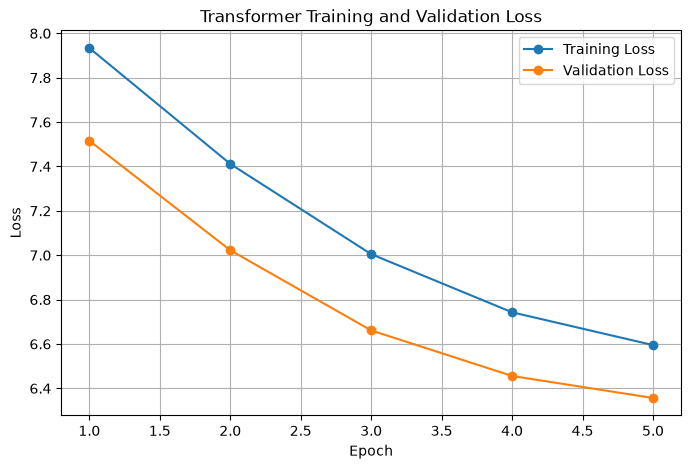

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_history) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    train_history,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    val_history,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Transformer Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
test_loss = validate(
    model=model,
    data_loader=test_loader,
    criterion=criterion
)

print("Test loss:", test_loss)

Test loss: 6.309783322470529


In [ ]:
#Decode Token IDs Back to Text
id_to_token = {
    int(token_id): token
    for token, token_id in token_to_id.items()
}

def decode_tokens(token_ids):
    """
    Convert token IDs back into readable text.
    """
    
    tokens = [
        id_to_token.get(int(token_id), "<UNK>")
        for token_id in token_ids
    ]
    
    return " ".join(tokens)


print(decode_tokens([
    BOS_ID,
    2869,
    368,
    430,
    EOS_ID
]))

<BOS> Among patients receiving <EOS>


In [ ]:
#Basic Greedy Generation
def generate_text(
    model,
    source,
    max_length=127
):
    """
    Generate text autoregressively using greedy decoding.
    """

    model.eval()

    generated = torch.tensor(
        [[BOS_ID]],
        dtype=torch.long
    )

    with torch.no_grad():

        for _ in range(max_length - 1):

            outputs = model(
                source=source,
                decoder_input=generated
            )

            logits = outputs["logits"]

            next_token_logits = logits[:, -1, :]

            next_token_id = torch.argmax(
                next_token_logits,
                dim=-1,
                keepdim=True
            )

            generated = torch.cat(
                [generated, next_token_id],
                dim=1
            )

            if next_token_id.item() == EOS_ID:
                break

    return generated

In [ ]:
#Generate an Answer
source_sample = test_data["source"][0].unsqueeze(0)

generated_ids = generate_text(
    model=model,
    source=source_sample,
    max_length=50
)

generated_text = decode_tokens(
    generated_ids[0]
)

print("Generated answer:")
print(generated_text)

Generated answer:
<BOS> The of the of the of the of the of the of the of the of the of the of the . <EOS>


In [ ]:
#Compare Input, Actual Answer, and Generated Answer
source_index = 0

source_ids = test_data["source"][source_index].unsqueeze(0)

generated_ids = generate_text(
    model=model,
    source=source_ids,
    max_length=50
)

actual_answer_ids = test_data["decoder_target"][source_index]

print("GENERATED ANSWER:")
print(decode_tokens(generated_ids[0]))

print("\nACTUAL ANSWER:")
print(decode_tokens(actual_answer_ids))

GENERATED ANSWER:
<BOS> The of the of the of the of the of the of the of the of the of the of the . <EOS>

ACTUAL ANSWER:
Having a regular primary care clinician is <UNK> in <UNK> , although team care among physicians is also widely <UNK> . For young children , having a regular clinician is associated with modest gains in interpersonal quality and no differences in content of <UNK> guidance . The benefit of having a regular clinician may primarily occur in interpersonal quality for subgroups of young children . <EOS> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD>


In [ ]:
#Inspect First-Token Prediction
model.eval()

source_sample = test_data["source"][0].unsqueeze(0)

decoder_input = torch.tensor(
    [[BOS_ID]],
    dtype=torch.long
)

with torch.no_grad():
    outputs = model(
        source=source_sample,
        decoder_input=decoder_input
    )

logits = outputs["logits"]

first_token_logits = logits[:, -1, :]

probabilities = torch.softmax(
    first_token_logits,
    dim=-1
)

top_probabilities, top_token_ids = torch.topk(
    probabilities,
    k=10,
    dim=-1
)

print("Top 10 predicted tokens:\n")

for probability, token_id in zip(
    top_probabilities[0],
    top_token_ids[0]
):
    token = id_to_token[int(token_id)]
    
    print(
        f"{token:20s} "
        f"{probability.item():.4f}"
    )

Top 10 predicted tokens:

The                  0.0735
<UNK>                0.0115
in                   0.0071
In                   0.0067
of                   0.0061
with                 0.0054
This                 0.0047
the                  0.0044
be                   0.0040
We                   0.0037


In [ ]:
#Temprature Sampling
def generate_text_sampling(
    model,
    source,
    max_length=127,
    temperature=1.0
):
    """
    Generate text using temperature sampling.
    """

    model.eval()

    generated = torch.tensor(
        [[BOS_ID]],
        dtype=torch.long
    )

    with torch.no_grad():

        for _ in range(max_length - 1):

            outputs = model(
                source=source,
                decoder_input=generated
            )

            logits = outputs["logits"]

            next_token_logits = logits[:, -1, :]

            # Temperature controls randomness.
            next_token_logits = (
                next_token_logits / temperature
            )

            probabilities = torch.softmax(
                next_token_logits,
                dim=-1
            )

            next_token_id = torch.multinomial(
                probabilities,
                num_samples=1
            )

            generated = torch.cat(
                [generated, next_token_id],
                dim=1
            )

            if next_token_id.item() == EOS_ID:
                break

    return generated

In [ ]:
#Generate with Temperature
source_sample = test_data["source"][0].unsqueeze(0)

generated_ids = generate_text_sampling(
    model=model,
    source=source_sample,
    max_length=50,
    temperature=0.8
)

print("Generated answer:")
print(decode_tokens(generated_ids[0]))

Generated answer:
<BOS> the could patients the a should benefits myotomy LAGB ETS . <EOS>


In [ ]:
ADDITIONAL_EPOCHS = 5

additional_train_history, additional_val_history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    num_epochs=ADDITIONAL_EPOCHS
)

Epoch 1/5 | Train Loss: 6.5148 | Val Loss: 6.2954
Epoch 2/5 | Train Loss: 6.4454 | Val Loss: 6.2393
Epoch 3/5 | Train Loss: 6.3850 | Val Loss: 6.1898
Epoch 4/5 | Train Loss: 6.3187 | Val Loss: 6.1512
Epoch 5/5 | Train Loss: 6.2608 | Val Loss: 6.1076


In [ ]:
#Early-Stopping Training Function
def train_model_early_stopping(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    max_epochs=30,
    patience=3,
    min_delta=0.001
):
    """
    Train the Transformer with early stopping.

    Training stops when validation loss does not
    improve for 'patience' consecutive epochs.
    """

    train_history = []
    val_history = []

    best_val_loss = float("inf")
    best_model_state = None

    epochs_without_improvement = 0

    for epoch in range(max_epochs):

        # Train for one epoch
        train_loss = train_one_epoch(
            model=model,
            data_loader=train_loader,
            criterion=criterion,
            optimizer=optimizer
        )

        # Validate
        val_loss = validate(
            model=model,
            data_loader=val_loader,
            criterion=criterion
        )

        # Store history
        train_history.append(train_loss)
        val_history.append(val_loss)

        print(
            f"Epoch {epoch + 1}/{max_epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

        # Check whether validation improved
        if val_loss < best_val_loss - min_delta:

            best_val_loss = val_loss

            best_model_state = {
                key: value.detach().clone()
                for key, value in model.state_dict().items()
            }

            epochs_without_improvement = 0

            print("  → Validation improved. Best model saved.")

        else:

            epochs_without_improvement += 1

            print(
                f"  → No significant improvement "
                f"({epochs_without_improvement}/{patience})"
            )

        # Early stopping condition
        if epochs_without_improvement >= patience:

            print("\nEarly stopping triggered.")
            break

    # Restore best model
    if best_model_state is not None:

        model.load_state_dict(best_model_state)

        print(
            f"Best validation loss restored: "
            f"{best_val_loss:.4f}"
        )

    return train_history, val_history

In [ ]:
EARLY_STOPPING_EPOCHS = 30

early_train_history, early_val_history = train_model_early_stopping(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    max_epochs=EARLY_STOPPING_EPOCHS,
    patience=3,
    min_delta=0.001
)

Epoch 1/30 | Train Loss: 6.2072 | Val Loss: 6.0766
  → Validation improved. Best model saved.
Epoch 2/30 | Train Loss: 6.1525 | Val Loss: 6.0405
  → Validation improved. Best model saved.
Epoch 3/30 | Train Loss: 6.1005 | Val Loss: 6.0108
  → Validation improved. Best model saved.
Epoch 4/30 | Train Loss: 6.0444 | Val Loss: 5.9858
  → Validation improved. Best model saved.
Epoch 5/30 | Train Loss: 5.9949 | Val Loss: 5.9736
  → Validation improved. Best model saved.
Epoch 6/30 | Train Loss: 5.9477 | Val Loss: 5.9366
  → Validation improved. Best model saved.
Epoch 7/30 | Train Loss: 5.8944 | Val Loss: 5.9077
  → Validation improved. Best model saved.
Epoch 8/30 | Train Loss: 5.8467 | Val Loss: 5.8936
  → Validation improved. Best model saved.
Epoch 9/30 | Train Loss: 5.7932 | Val Loss: 5.8800
  → Validation improved. Best model saved.
Epoch 10/30 | Train Loss: 5.7520 | Val Loss: 5.8581
  → Validation improved. Best model saved.
Epoch 11/30 | Train Loss: 5.7021 | Val Loss: 5.8358
  → Val

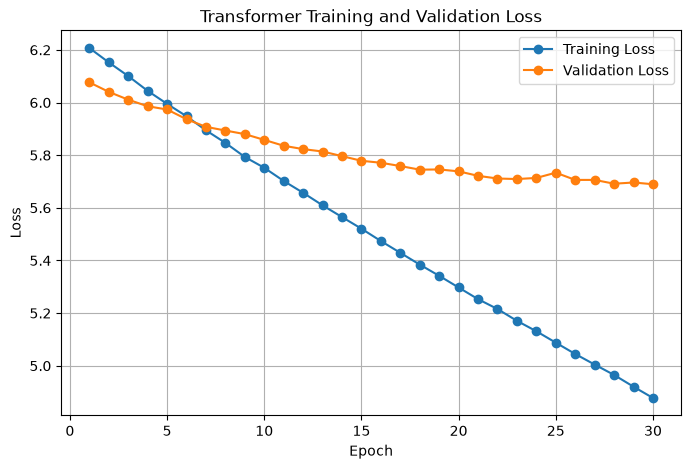

In [ ]:
#plot the complete early-stopping training history
import matplotlib.pyplot as plt

epochs = range(1, len(early_train_history) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    early_train_history,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    early_val_history,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Transformer Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
test_loss = validate(
    model=model,
    data_loader=test_loader,
    criterion=criterion
)

print("Final Test Loss:", test_loss)

Final Test Loss: 5.662307603018625


In [ ]:
source_sample = test_data["source"][0].unsqueeze(0)

generated_ids = generate_text(
    model=model,
    source=source_sample,
    max_length=50
)

generated_text = decode_tokens(
    generated_ids[0]
)

print("Generated answer:")
print(generated_text)

Generated answer:
<BOS> The results of the study , the study , the present study , the first that the first - based on the first - up of the first - based on the first - based on the first - based on the <UNK> , and <UNK> , and <UNK>


In [ ]:
#Evaluate the model quantitatively
model.eval()

source_batch, decoder_input_batch, decoder_target_batch = next(iter(test_loader))

with torch.no_grad():
    outputs = model(
        source=source_batch,
        decoder_input=decoder_input_batch
    )

logits = outputs["logits"]

predicted_ids = torch.argmax(
    logits,
    dim=-1
)

# Ignore padding positions
valid_positions = decoder_target_batch != PAD_ID

correct_predictions = (
    predicted_ids[valid_positions]
    == decoder_target_batch[valid_positions]
)

token_accuracy = (
    correct_predictions.float().mean().item()
)

print("Test batch token accuracy:", token_accuracy)
print("Percentage:", token_accuracy * 100)

Test batch token accuracy: 0.18385092914104462
Percentage: 18.38509291410446


In [ ]:
def evaluate_token_accuracy(
    model,
    data_loader
):
    """
    Calculate token-level accuracy across
    the complete dataset.
    """

    model.eval()

    total_correct = 0
    total_tokens = 0

    with torch.no_grad():

        for source_batch, decoder_input_batch, decoder_target_batch in data_loader:

            outputs = model(
                source=source_batch,
                decoder_input=decoder_input_batch
            )

            logits = outputs["logits"]

            predicted_ids = torch.argmax(
                logits,
                dim=-1
            )

            valid_positions = (
                decoder_target_batch != PAD_ID
            )

            total_correct += (
                (predicted_ids[valid_positions]
                 == decoder_target_batch[valid_positions])
                .sum()
                .item()
            )

            total_tokens += (
                valid_positions
                .sum()
                .item()
            )

    accuracy = total_correct / total_tokens

    return accuracy


test_token_accuracy = evaluate_token_accuracy(
    model=model,
    data_loader=test_loader
)

print("Full Test Token Accuracy:", test_token_accuracy)
print("Percentage:", test_token_accuracy * 100)

Full Test Token Accuracy: 0.16806181584030908
Percentage: 16.806181584030906


In [ ]:
#Comparing 5 test example
model.eval()

for i in range(5):

    source_sample = test_data["source"][i].unsqueeze(0)

    generated_ids = generate_text(
        model=model,
        source=source_sample,
        max_length=50
    )

    generated_text = decode_tokens(
        generated_ids[0]
    )

    actual_text = decode_tokens(
        test_data["decoder_target"][i]
    )

    print("=" * 80)
    print(f"Example {i + 1}")
    print("\nGenerated:")
    print(generated_text)

    print("\nActual:")
    print(actual_text)

Example 1

Generated:
<BOS> The results of the study , the study , the present study , the first that the first - based on the first - up of the first - based on the first - based on the first - based on the <UNK> , and <UNK> , and <UNK>

Actual:
Having a regular primary care clinician is <UNK> in <UNK> , although team care among physicians is also widely <UNK> . For young children , having a regular clinician is associated with modest gains in interpersonal quality and no differences in content of <UNK> guidance . The benefit of having a regular clinician may primarily occur in interpersonal quality for subgroups of young children . <EOS> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD

In [ ]:
# ============================================
# MODEL + DATASET DIAGNOSTICS
# ============================================

import torch

print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

# Vocabulary
print(f"Vocabulary size:        {len(token_to_id):,}")

# Dataset token counts
train_source_tokens = train_data["source"].numel()
train_target_tokens = train_data["decoder_target"].numel()

val_source_tokens = val_data["source"].numel()
val_target_tokens = val_data["decoder_target"].numel()

test_source_tokens = test_data["source"].numel()
test_target_tokens = test_data["decoder_target"].numel()

print(f"Train source tokens:    {train_source_tokens:,}")
print(f"Train target tokens:    {train_target_tokens:,}")
print(f"Train total tokens:     {train_source_tokens + train_target_tokens:,}")

print(f"Validation source:      {val_source_tokens:,}")
print(f"Validation target:      {val_target_tokens:,}")
print(f"Validation total:       {val_source_tokens + val_target_tokens:,}")

print(f"Test source tokens:     {test_source_tokens:,}")
print(f"Test target tokens:     {test_target_tokens:,}")
print(f"Test total tokens:      {test_source_tokens + test_target_tokens:,}")

print()
print("=" * 60)
print("MODEL ARCHITECTURE")
print("=" * 60)

print(f"D_MODEL:                {D_MODEL}")
print(f"Attention heads:        {NUM_HEADS}")
print(f"Head dimension:         {D_MODEL // NUM_HEADS}")
print(f"Encoder layers:         {NUM_ENCODER_LAYERS}")
print(f"Decoder layers:         {NUM_DECODER_LAYERS}")
print(f"Feed-forward dimension: {D_FF}")
print(f"Dropout:                {DROPOUT}")

# Model parameter count
total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(f"Total parameters:       {total_params:,}")
print(f"Trainable parameters:   {trainable_params:,}")

print()
print("=" * 60)
print("SEQUENCE LENGTHS")
print("=" * 60)

print(f"Source max length:      {train_data['source'].shape[1]}")
print(f"Target max length:      {train_data['decoder_target'].shape[1]}")
print(f"Batch size:             {train_loader.batch_size}")

print()
print("=" * 60)
print("OPTIMIZATION")
print("=" * 60)

print(f"Optimizer:              {optimizer.__class__.__name__}")

# Print optimizer settings
for i, param_group in enumerate(optimizer.param_groups):
    print(f"Parameter group {i}:")
    print(f"  Learning rate:        {param_group['lr']}")
    print(f"  Weight decay:         {param_group.get('weight_decay', 0)}")
    print(f"  Betas:                {param_group.get('betas', 'N/A')}")

print(f"Loss function:          {criterion.__class__.__name__}")
print(f"Ignore index:           {criterion.ignore_index}")

print()
print("=" * 60)
print("CURRENT TRAINING RESULTS")
print("=" * 60)

print(f"Best validation loss:   {min(val_history):.4f}")
print(f"Final validation loss:  {val_history[-1]:.4f}")
print(f"Final training loss:    {train_history[-1]:.4f}")

print()
print("=" * 60)
print("DEVICE")
print("=" * 60)

print(f"PyTorch version:        {torch.__version__}")
print(f"Device:                 {next(model.parameters()).device}")
print(f"CUDA available:         {torch.cuda.is_available()}")

DATASET INFORMATION
Vocabulary size:        9,537
Train source tokens:    409,600
Train target tokens:    101,600
Train total tokens:     511,200
Validation source:      51,200
Validation target:      12,700
Validation total:       63,900
Test source tokens:     51,200
Test target tokens:     12,700
Test total tokens:      63,900

MODEL ARCHITECTURE
D_MODEL:                128
Attention heads:        4
Head dimension:         32
Encoder layers:         2
Decoder layers:         2
Feed-forward dimension: 512
Dropout:                0.1
Total parameters:       4,597,441
Trainable parameters:   4,597,441

SEQUENCE LENGTHS
Source max length:      512
Target max length:      127
Batch size:             16

OPTIMIZATION
Optimizer:              Adam
Parameter group 0:
  Learning rate:        0.0001
  Weight decay:         0
  Betas:                (0.9, 0.999)
Loss function:          CrossEntropyLoss
Ignore index:           0

CURRENT TRAINING RESULTS
Best validation loss:   6.3565
Final vali